In [2]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *


from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
from skimage import measure

In [4]:
prefix = '/mnt/staging/' # or 
mouse='cm229'

step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"


save_path = str(FIGURES / "figure2") + "/"


In [5]:
load_path = str(PREPARES / "registration") + "/"
dict_transform = load_pickle(load_path+'dict_transform')
M=dict_transform[mouse]


In [6]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_58288/1478694046.py:6: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


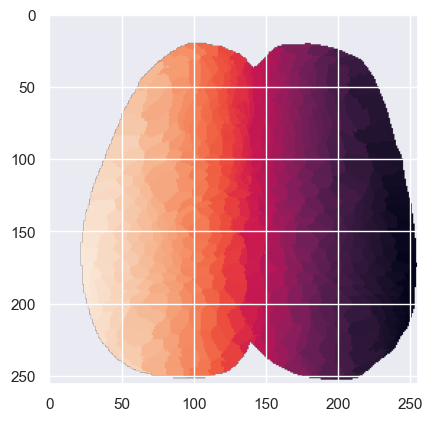

In [7]:
with h5py.File(step_0_root+mouse+'/'+'idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

# boop

In [8]:
# bodyparts = ['RFP','LFP','nose','RHP','LHP','mouth','tail','LW']
bodyparts = ['RFP','LFP','RHP','LHP','mouth','nose','RW','tail']
day8_dict = { 
    'runF':
    "boop_on = 'RFP';stim_frames_raw="+"[ 3570, 10715, 14498];",
      'runN':"boop_on = 'RFP';stim_frames_raw=[1727,  10735, 12562, 14372];",
 'runG':
    "boop_on = 'LFP';stim_frames_raw="+"[2040, 3790, 7360, 9173, 10960, 12690, 14428, 16300];",
 'runH':
    "boop_on = 'RHP';stim_frames_raw="+"[9083, 10993, 12750, 14510, 16235];",
 'runI':
    "boop_on = 'LHP';stim_frames_raw="+"[4113, 5687, 7223, 9014, 12660, 14400, 16100];",
 'runJ':
    "boop_on = 'mouth';stim_frames_raw="+"[3950, 5710, 7525, 9346, 11186, 12982, 14749, 16430];",
 'runK':
    "boop_on = 'nose';stim_frames_raw="+"[1913, 3820, 5540, 7360, 9115, 11011, 12750, 14550, 16320];",
  'runL':
    "boop_on = 'RW';stim_frames_raw="+"[1971, 3600, 5511, 7295, 12647, 14547];",
  'runM':
    "boop_on = 'tail';stim_frames_raw="+"[1979, 3839, 5682, 7351, 9255, 10978, 12750, 14604, 16345];",
            }


In [9]:
file_list=[]
for i_run, run_id in enumerate(day8_dict.keys()):
    exec("file_list.append(glob.glob(step_1_root + mouse+'/8/{}*.mat', recursive=True)[0])".format(run_id))
# for i_run, run_id in enumerate(day4_dict.keys()):
#     exec("file_list.append(glob.glob(step_2_root + mouse+'/4/H_{}*.mat', recursive=True)[0])".format(run_id))

file_list

['/Volumes/WX/scratch/steps_data/step_1/cm229/8/runF_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runN_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runG_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runH_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runI_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runJ_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runK_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runL_stim_1.mat',
 '/Volumes/WX/scratch/steps_data/step_1/cm229/8/runM_stim_1.mat']

In [10]:
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 100
T_POST = 200
T = T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = {key:np.empty((256,256,T,0)) for key in bodyparts}
M_day_label = {key:np.empty((0)) for key in bodyparts}

for i_file,fname in enumerate(file_list): 
    ################################### identity 
    mouse = fname.split('step_1/')[1][0:5]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run_name = fname.split('_stim_1')[0].split('/'+day+'/')[1]
    run = run_name
    
    if day=='8':
        string = str(day8_dict[str(run_name)])
        exec(string);print(string[:15])
        
    stim_frames = np.round(np.array(stim_frames_raw)/4,decimals=-1).astype('int')
    
    total_frames = 8000
    start_stop_ind = pd.DataFrame(stim_frames)
    start_stop_ind = start_stop_ind[start_stop_ind[0]<total_frames-T_POST]
    for i in range(len(start_stop_ind)):
        
        cut_range = range(start_stop_ind.iloc[i,0]-T_PRE,start_stop_ind.iloc[i,0]+T_POST)

        with h5py.File(fname, "r") as f_H:
            m = f_H['m']
            C = np.array(f_H['C']['jrgeco'])
            S = np.array(f_H['S']['jrgeco'])[cut_range,:]
            # cut [-60,60] frames slice
            mask = np.array(f_H['mask'])
            # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
            nanidx = np.squeeze(m['nanidx'])==1
            CS = np.dot(S,C).transpose()
            jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
            jrgeco[:] = np.nan
            jrgeco[nanidx==True,:] = CS
            jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        jrgeco_dsl = jrgeco-np.mean(jrgeco[:,:,:80],axis=2)[:,:,np.newaxis]
        M_jrgeco[boop_on] = np.append(M_jrgeco[boop_on],jrgeco_dsl[:,:,:,np.newaxis],axis=3)
        M_day_label[boop_on] = np.append(M_day_label[boop_on],mouse_day+'_'+run)




boop_on = 'RFP'
boop_on = 'RFP'
boop_on = 'LFP'
boop_on = 'RHP'
boop_on = 'LHP'
boop_on = 'mout
boop_on = 'nose
boop_on = 'RW';
boop_on = 'tail


In [11]:
sns.set_style("whitegrid", {'axes.grid' : False})
avg_brain_maps = {key:[] for key in bodyparts}
contours = {key:[] for key in bodyparts}
clean_contours = {key:[] for key in bodyparts}
brightest_ind = {key:[] for key in bodyparts}
vmax_dict = {key:[] for key in bodyparts}
t_range_dict = {key:[] for key in bodyparts}

homunculus_rois = {key:[] for key in bodyparts}

In [12]:
from sklearn.preprocessing import minmax_scale

In [14]:
def build_bodypart_roi(
    name,
    t_range,
    vmax,
    bw_threshold,
    reject_contour,
    focus_range=(0.1, 1),
    title=None,
    show_bw_preview=True,
    abs_signal=False,
    mask_crop=None,
    source_key=None,
    stat_key=None,
):
    # stat_key lets vmax_dict/t_range_dict be written under a different key than `name`.
    # The original LV/RV cells wrote these two dicts before reassigning bodypart_name
    # from 'nose' to 'LV'/'RV', so both ended up keyed under 'nose' (clobbered twice,
    # RV last). Reproduced here via stat_key='nose' at the LV/RV call sites.
    t_range_dict[stat_key or name] = t_range
    signal = M_jrgeco[source_key or name]
    if abs_signal:
        signal = np.abs(signal)
    brain_map = np.mean(np.mean(signal, axis=-1)[:, :, t_range], axis=-1)
    brain_map = cv2.warpAffine(brain_map, M[0:2, :], (256, 256))
    vmax_dict[stat_key or name] = vmax

    plt.figure(figsize=(8, 3), dpi=300)
    plt.subplot(121)
    plt.imshow(brain_map, vmin=0, vmax=vmax, cmap='coolwarm')
    plt.colorbar()
    plt.xticks([]); plt.yticks([])
    plt.title(title or name)

    plt.subplot(122)
    bw = brain_map > bw_threshold
    if show_bw_preview:
        plt.imshow(bw)
    filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
    contours[name] = measure.find_contours(filled_bw, 0.8)
    if mask_crop is not None:
        filled_bw = mask_crop(filled_bw)

    filled_bw_nan = filled_bw.astype('float')
    filled_bw_nan[filled_bw_nan == 0] = np.nan
    focus_map = np.multiply(filled_bw_nan, brain_map)
    shape = focus_map.shape
    focus_map_scaled = minmax_scale(focus_map.ravel(), feature_range=focus_range).reshape(shape)
    plt.imshow(focus_map_scaled)
    homunculus_rois[name] = focus_map_scaled

    clean_contours[name] = [c for c in contours[name] if not reject_contour(c)]
    for c in clean_contours[name]:
        plt.plot(c[:, 1], c[:, 0], linewidth=2)

    avg_brain_maps[name] = brain_map
    return brain_map


def _reject_default(contour, min_len=20, row_cutoff=230):
    return len(contour) < min_len or np.any(contour[:, 0] > row_cutoff)


def _crop_rows(filled_bw, keep_below):
    filled_bw = filled_bw.copy()
    filled_bw[keep_below:, :] = False
    return filled_bw


def _crop_lv(filled_bw):
    filled_bw = filled_bw.copy()
    filled_bw[:182, :] = False
    filled_bw[:, :180] = False
    filled_bw[:, 240:] = False
    return filled_bw


def _crop_rv(filled_bw):
    filled_bw = filled_bw.copy()
    filled_bw[:182, :] = False
    filled_bw[:, 180:] = False
    filled_bw[:, 240:] = False
    return filled_bw


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

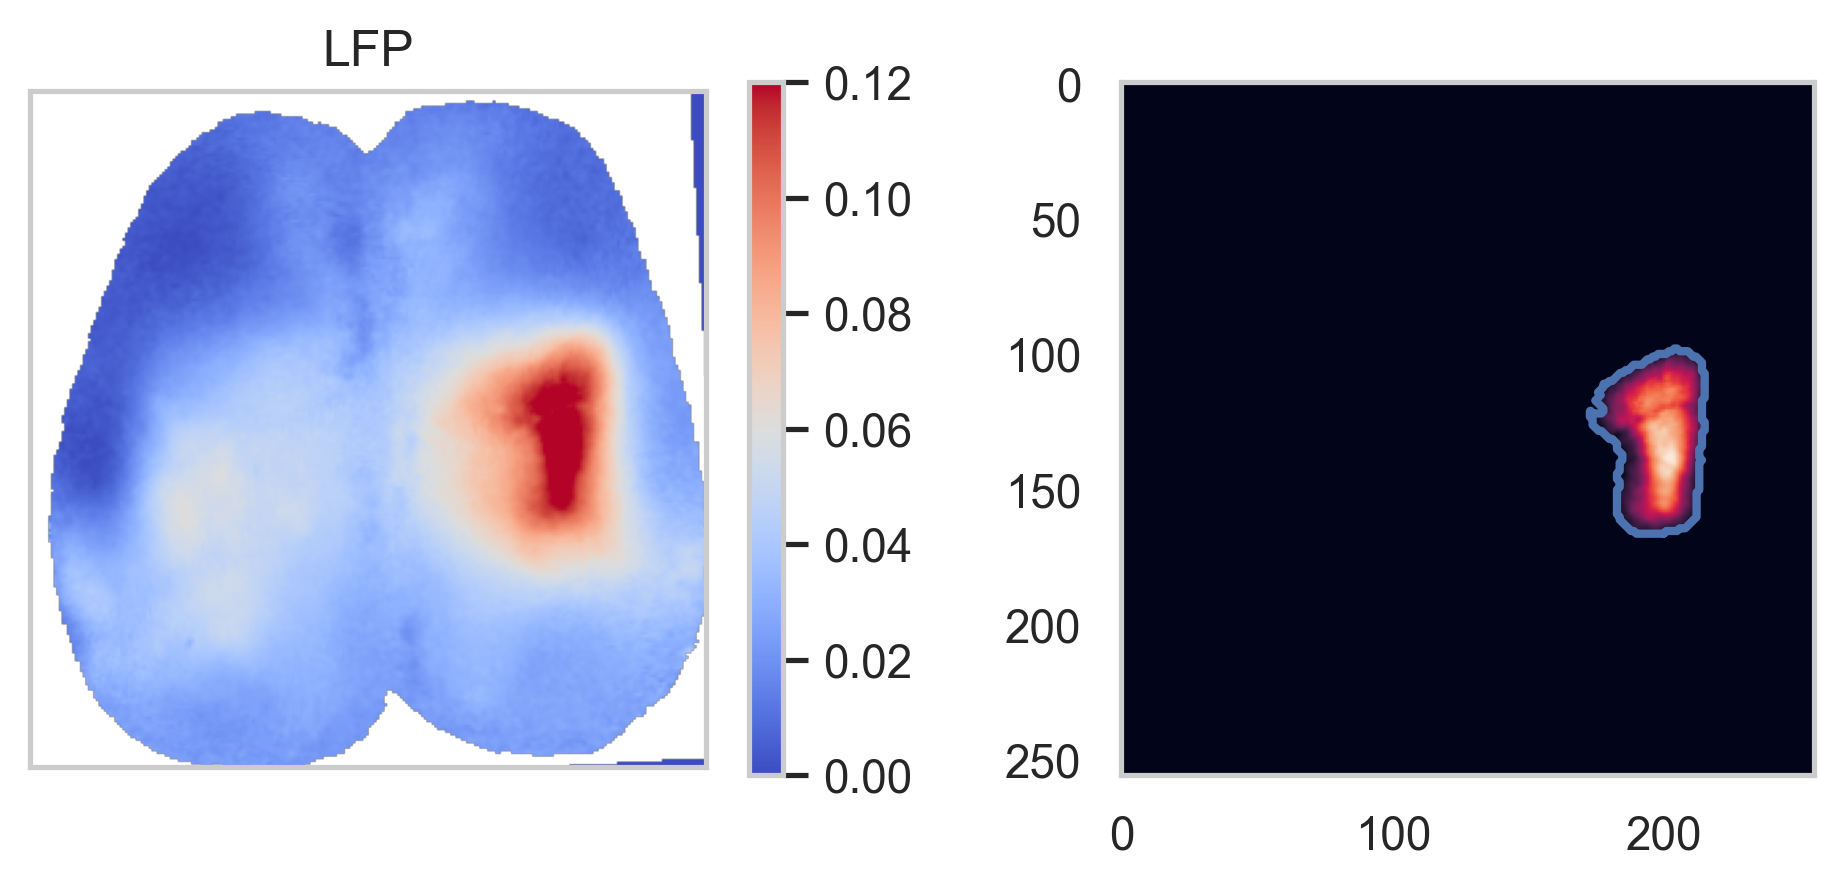

In [15]:
build_bodypart_roi(
    'LFP', range(T_PRE + 0, T_PRE + 60), vmax=0.12, bw_threshold=0.1 - 0.01,
    reject_contour=_reject_default,
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

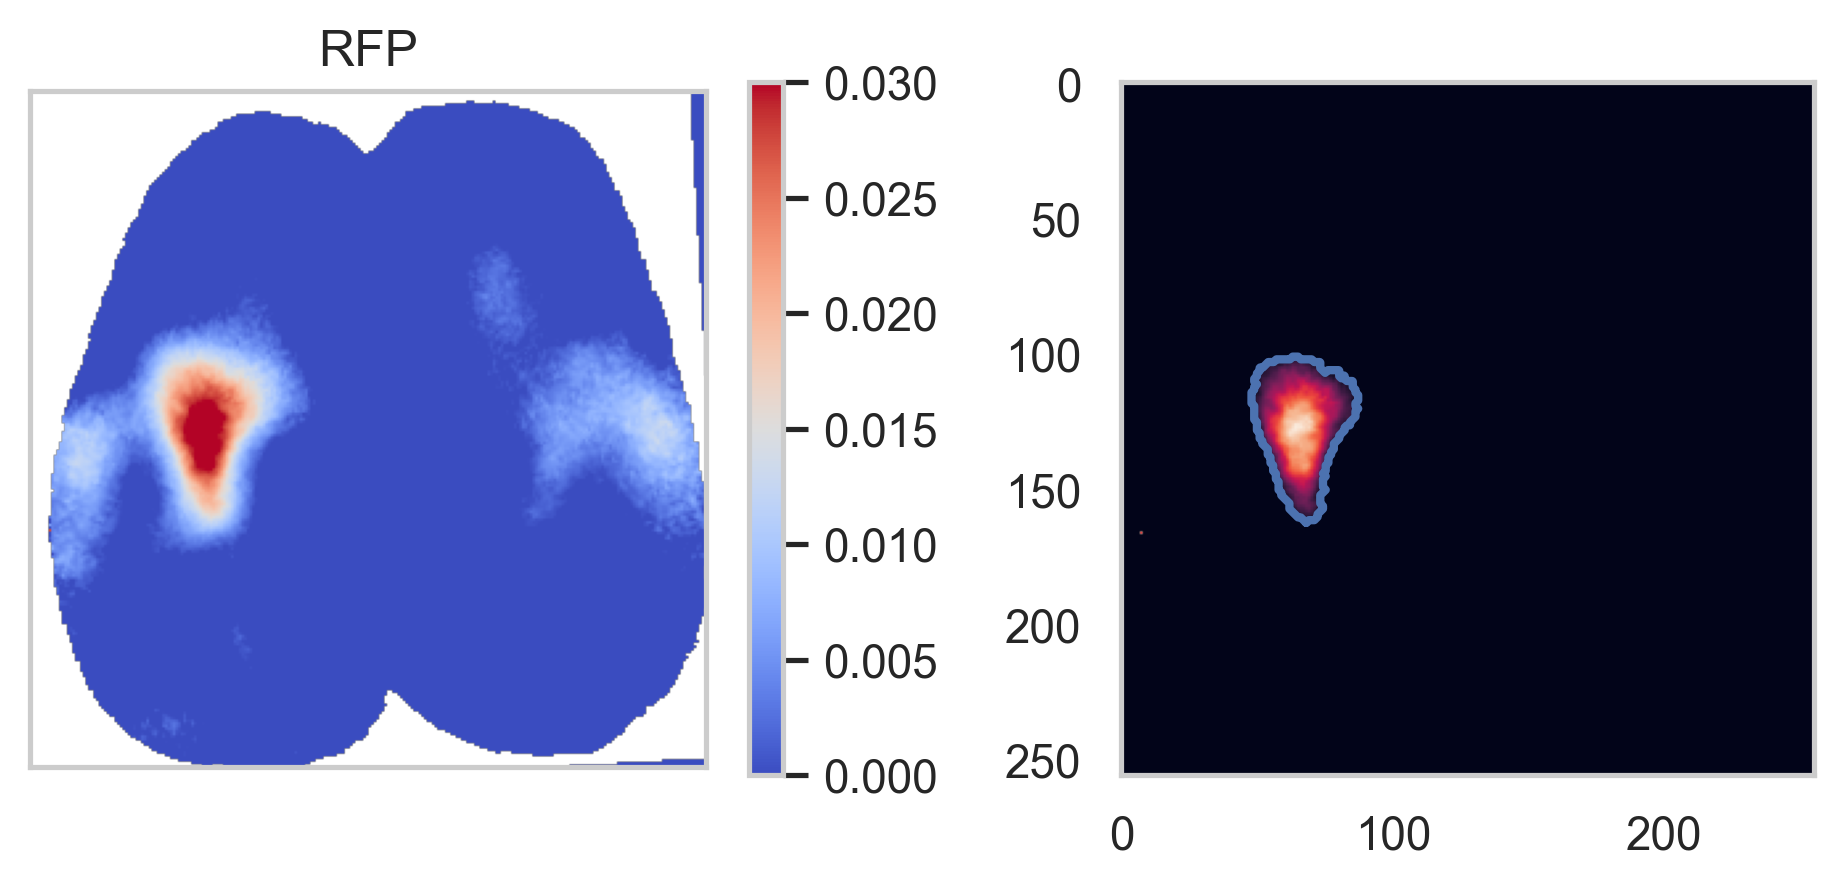

In [16]:
build_bodypart_roi(
    'RFP', range(T_PRE, T_PRE + 30), vmax=0.03, bw_threshold=0.019 - 0.005,
    reject_contour=_reject_default,
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

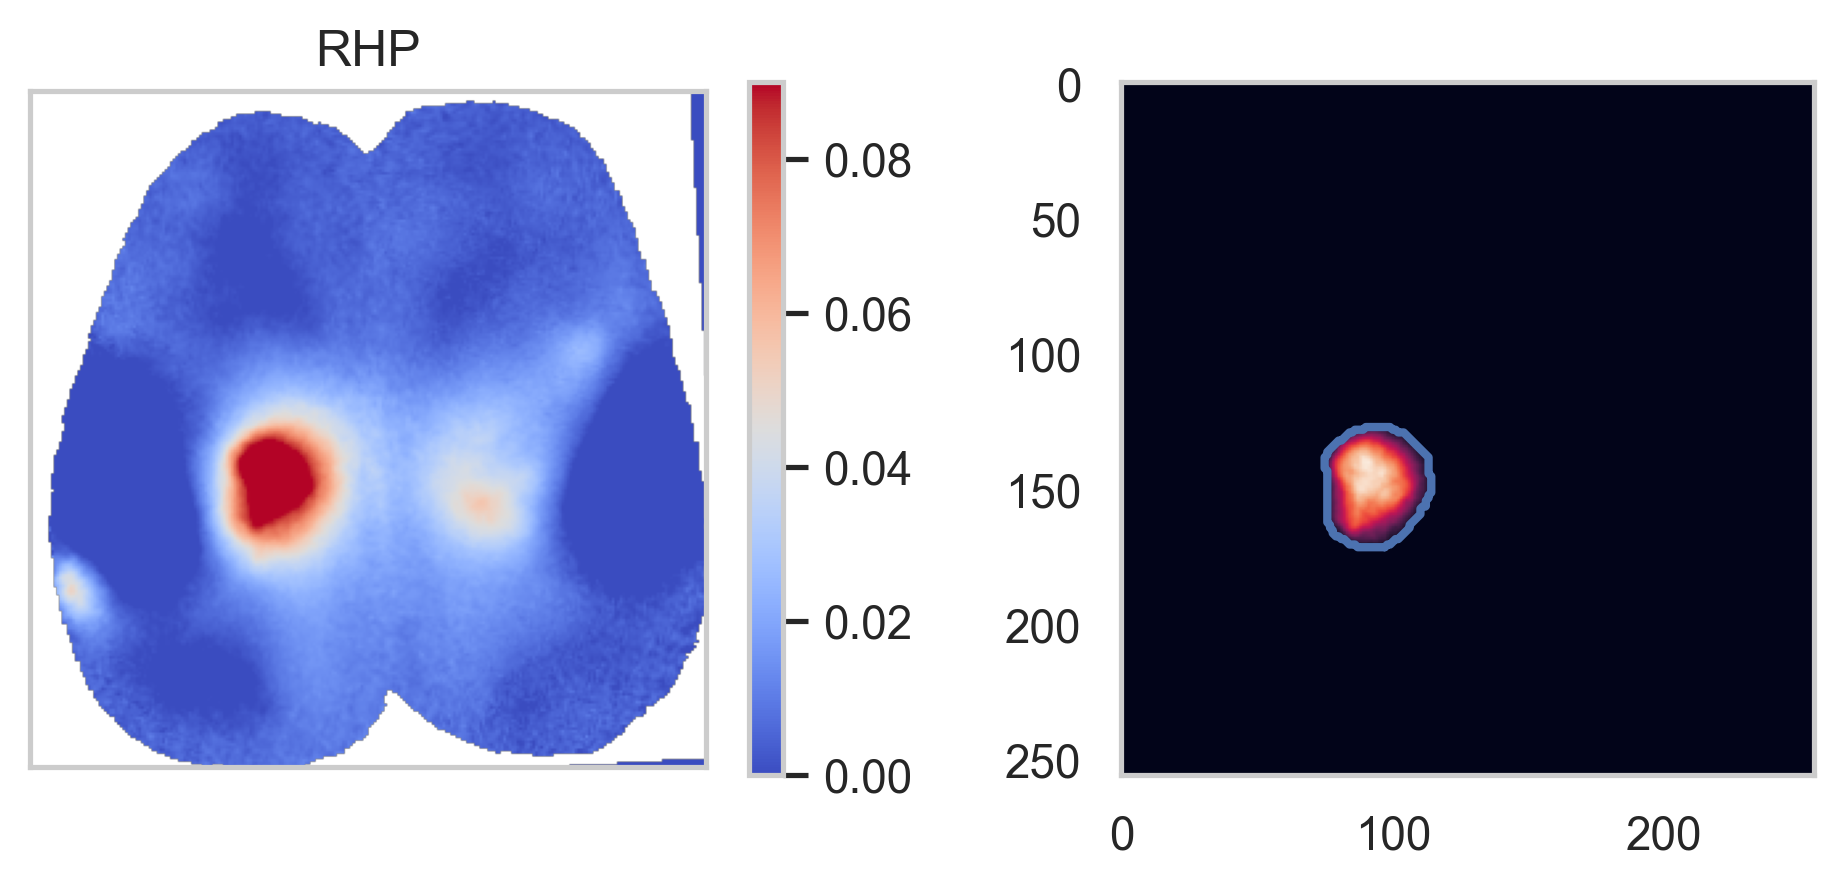

In [17]:
build_bodypart_roi(
    'RHP', range(T_PRE, T_PRE + 50), vmax=0.09, bw_threshold=0.07 - 0.01,
    reject_contour=_reject_default,
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

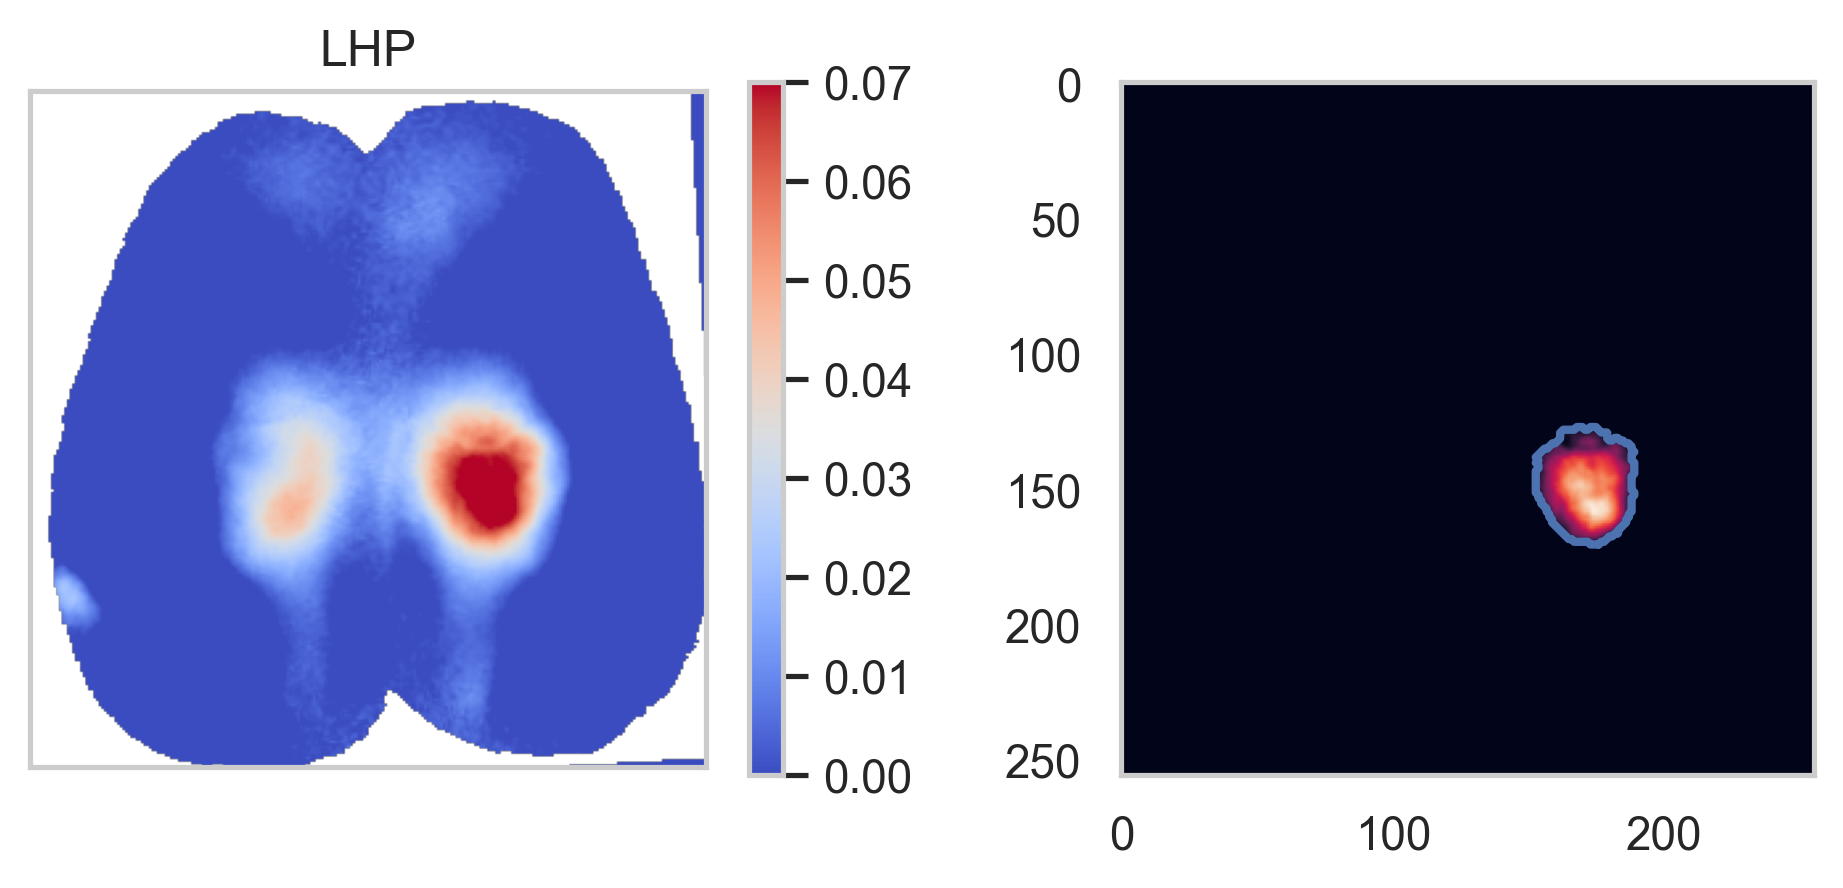

In [18]:
build_bodypart_roi(
    'LHP', range(T_PRE, T_PRE + 55), vmax=0.07, bw_threshold=0.05,
    reject_contour=_reject_default,
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

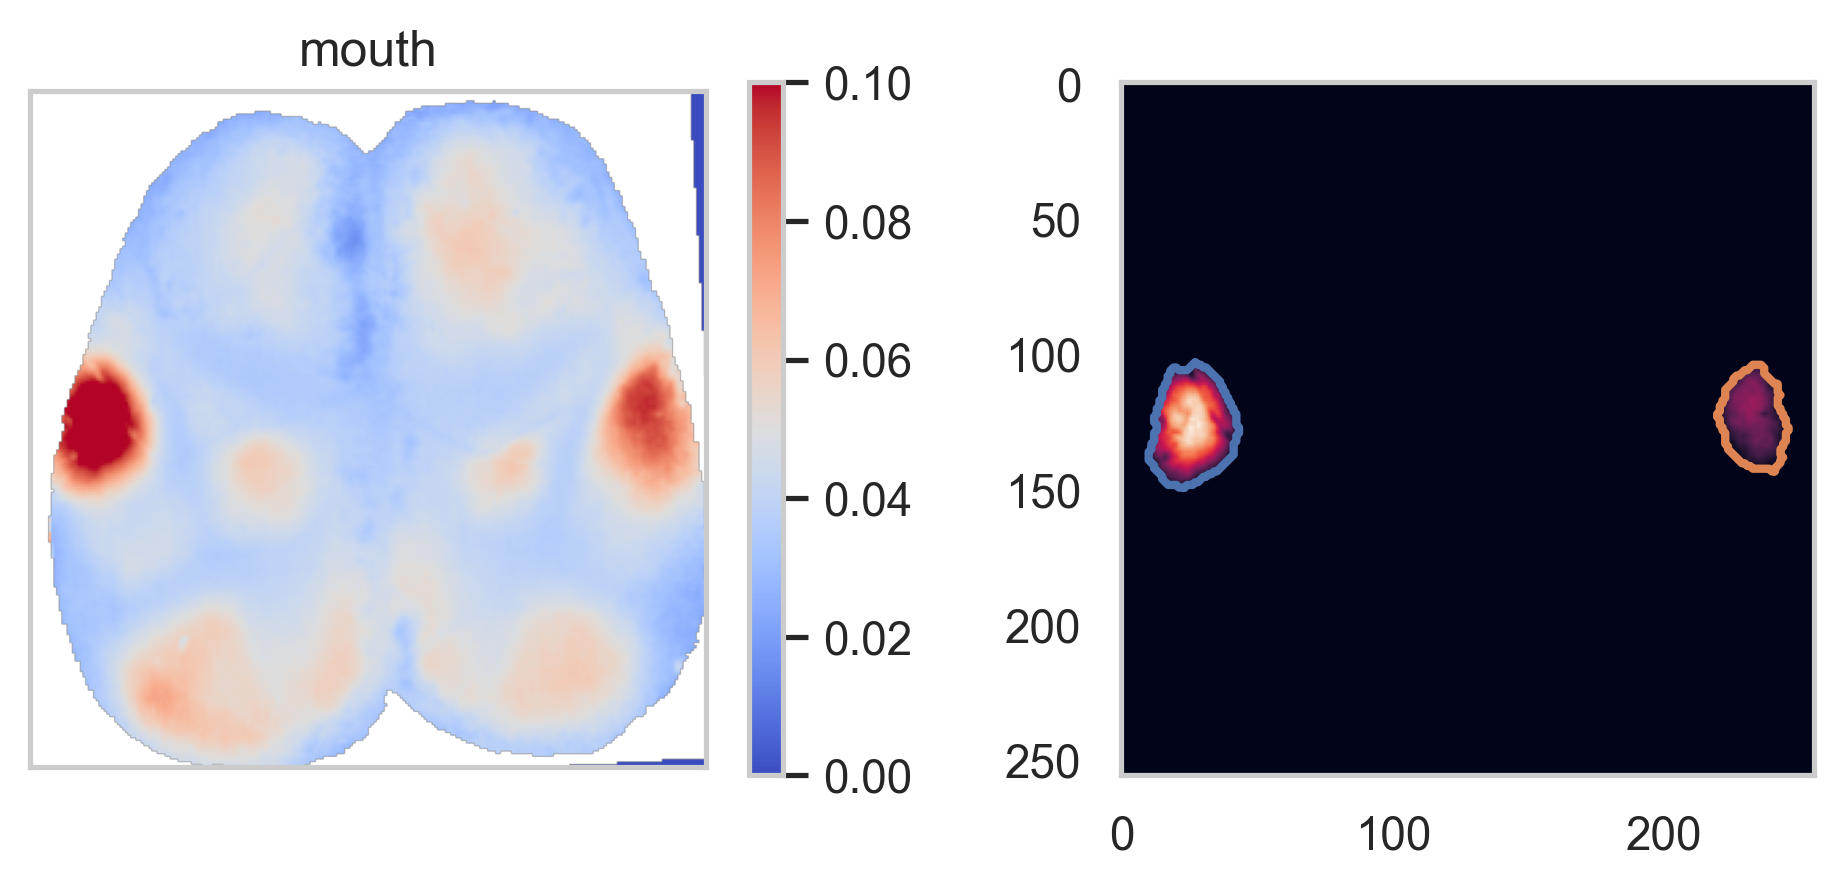

In [19]:
build_bodypart_roi(
    'mouth', range(T_PRE, T_PRE + 90), vmax=0.1, bw_threshold=0.08 - 0.005,
    abs_signal=True, focus_range=(0.2, 1),
    reject_contour=lambda c: _reject_default(c, min_len=50),
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

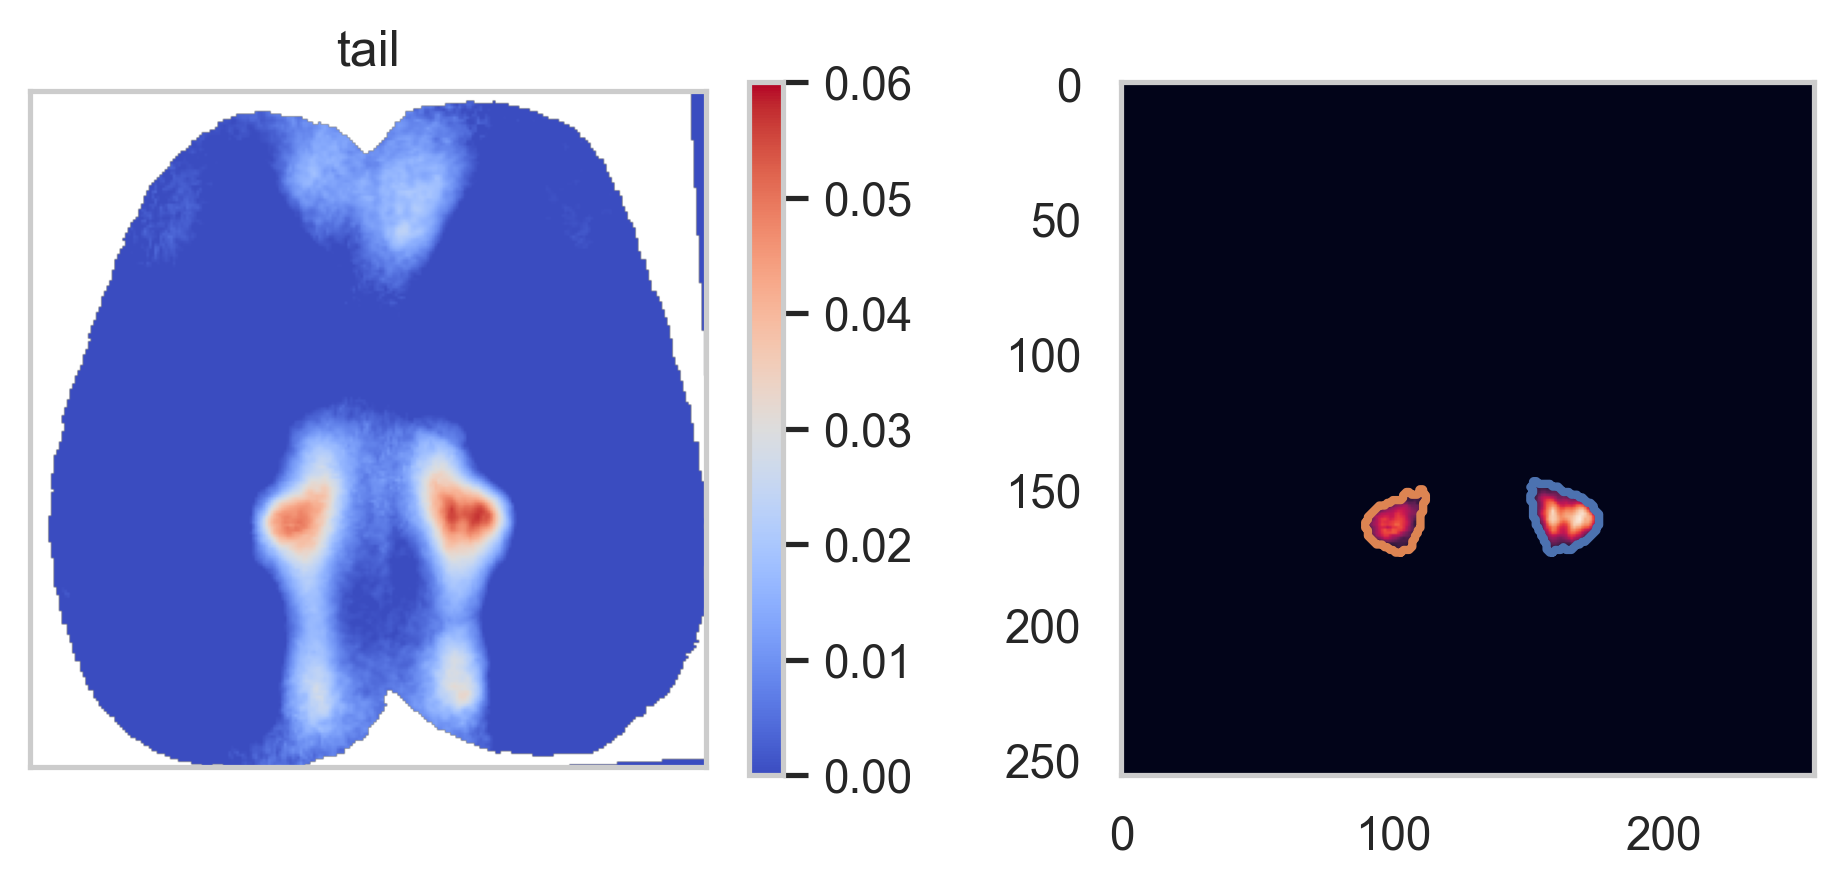

In [20]:
build_bodypart_roi(
    'tail', range(T_PRE + 10, T_PRE + 50), vmax=0.06, bw_threshold=0.04 - 0.005,
    focus_range=(0.12, 1),
    reject_contour=_reject_default,
)


In [21]:
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    # r_mask[r_mask == 0] = np.nan

    return r_mask


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

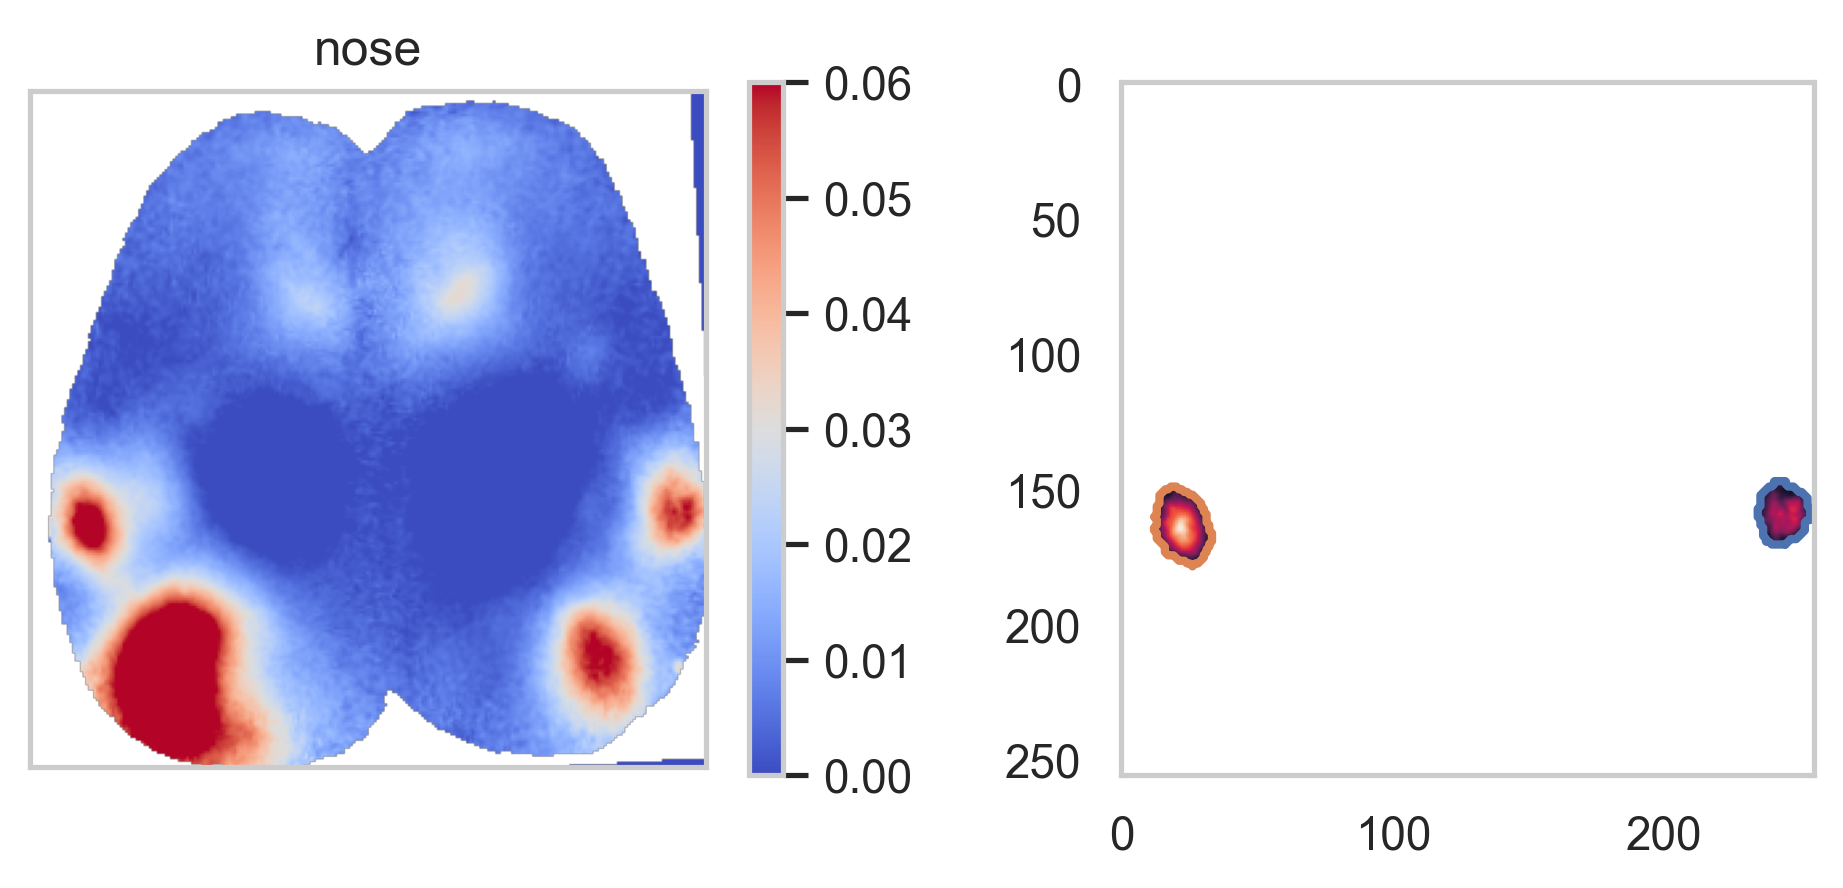

In [22]:
build_bodypart_roi(
    'nose', range(T_PRE, T_PRE + 20), vmax=0.06, bw_threshold=0.04,
    focus_range=(0.2, 1), show_bw_preview=False,
    mask_crop=lambda bw: _crop_rows(bw, 182),
    reject_contour=_reject_default,
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

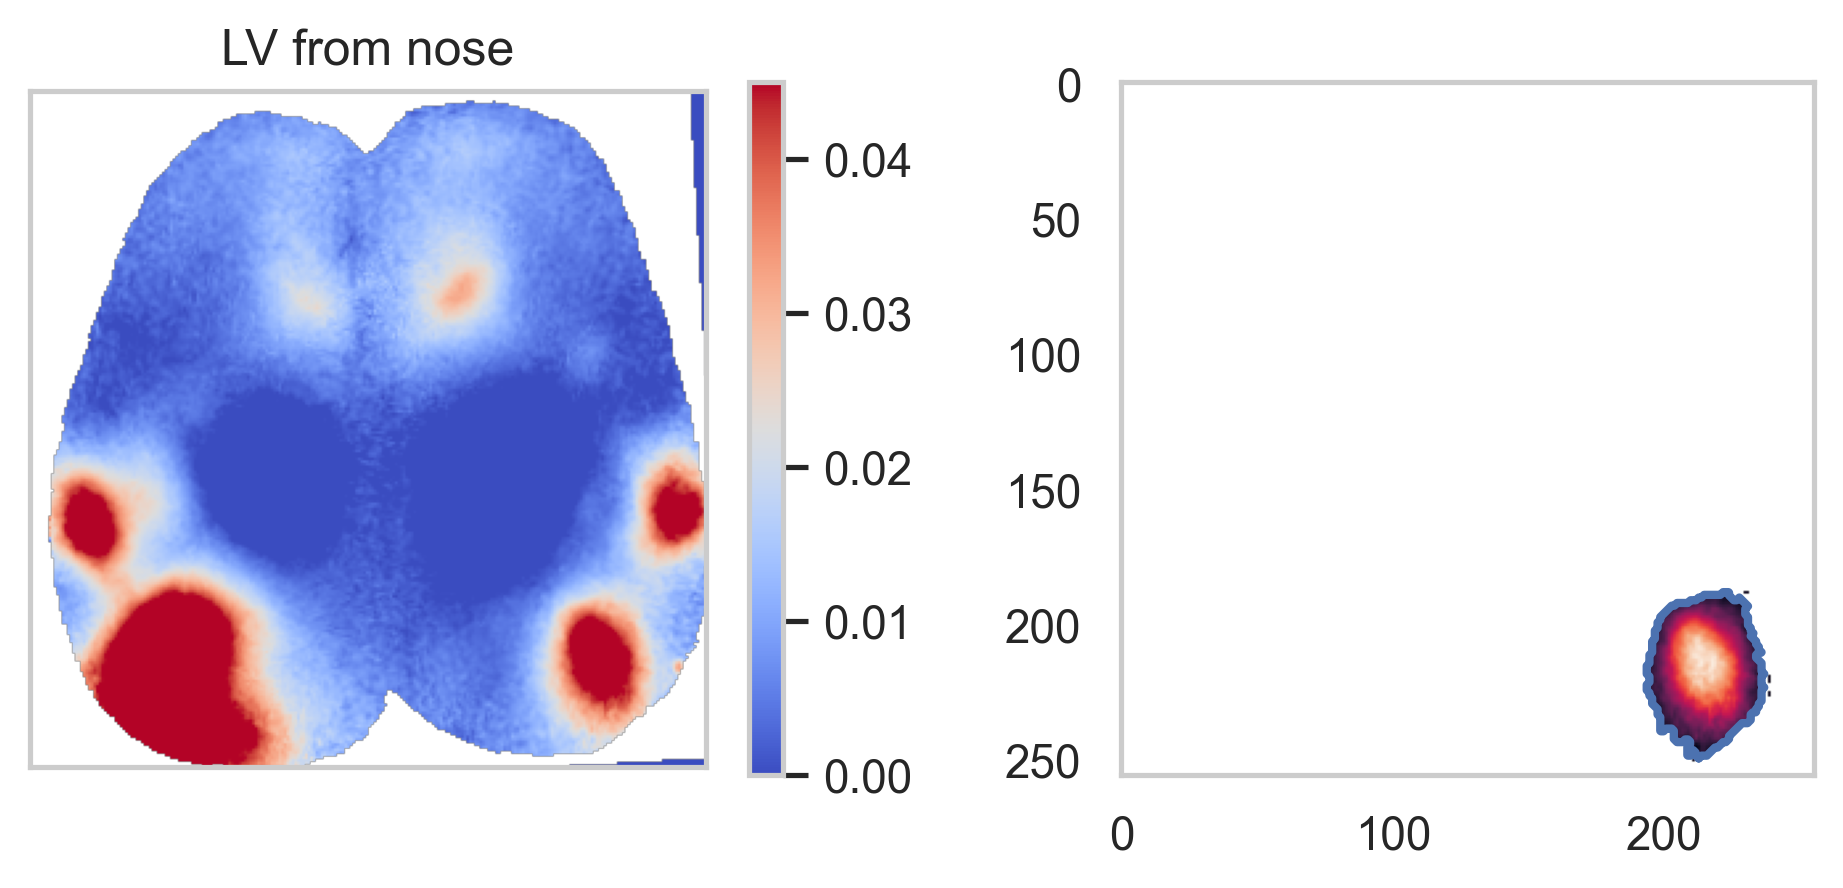

In [23]:
build_bodypart_roi(
    'LV', range(T_PRE, T_PRE + 20), vmax=0.045, bw_threshold=0.02,
    source_key='nose', stat_key='nose', title='LV from nose', focus_range=(0.2, 1),
    show_bw_preview=False, mask_crop=_crop_lv,
    reject_contour=lambda c: (
        np.any(c[:, 0] < 180) or np.any(c[:, 1] < 180) or len(c) < 30
    ),
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

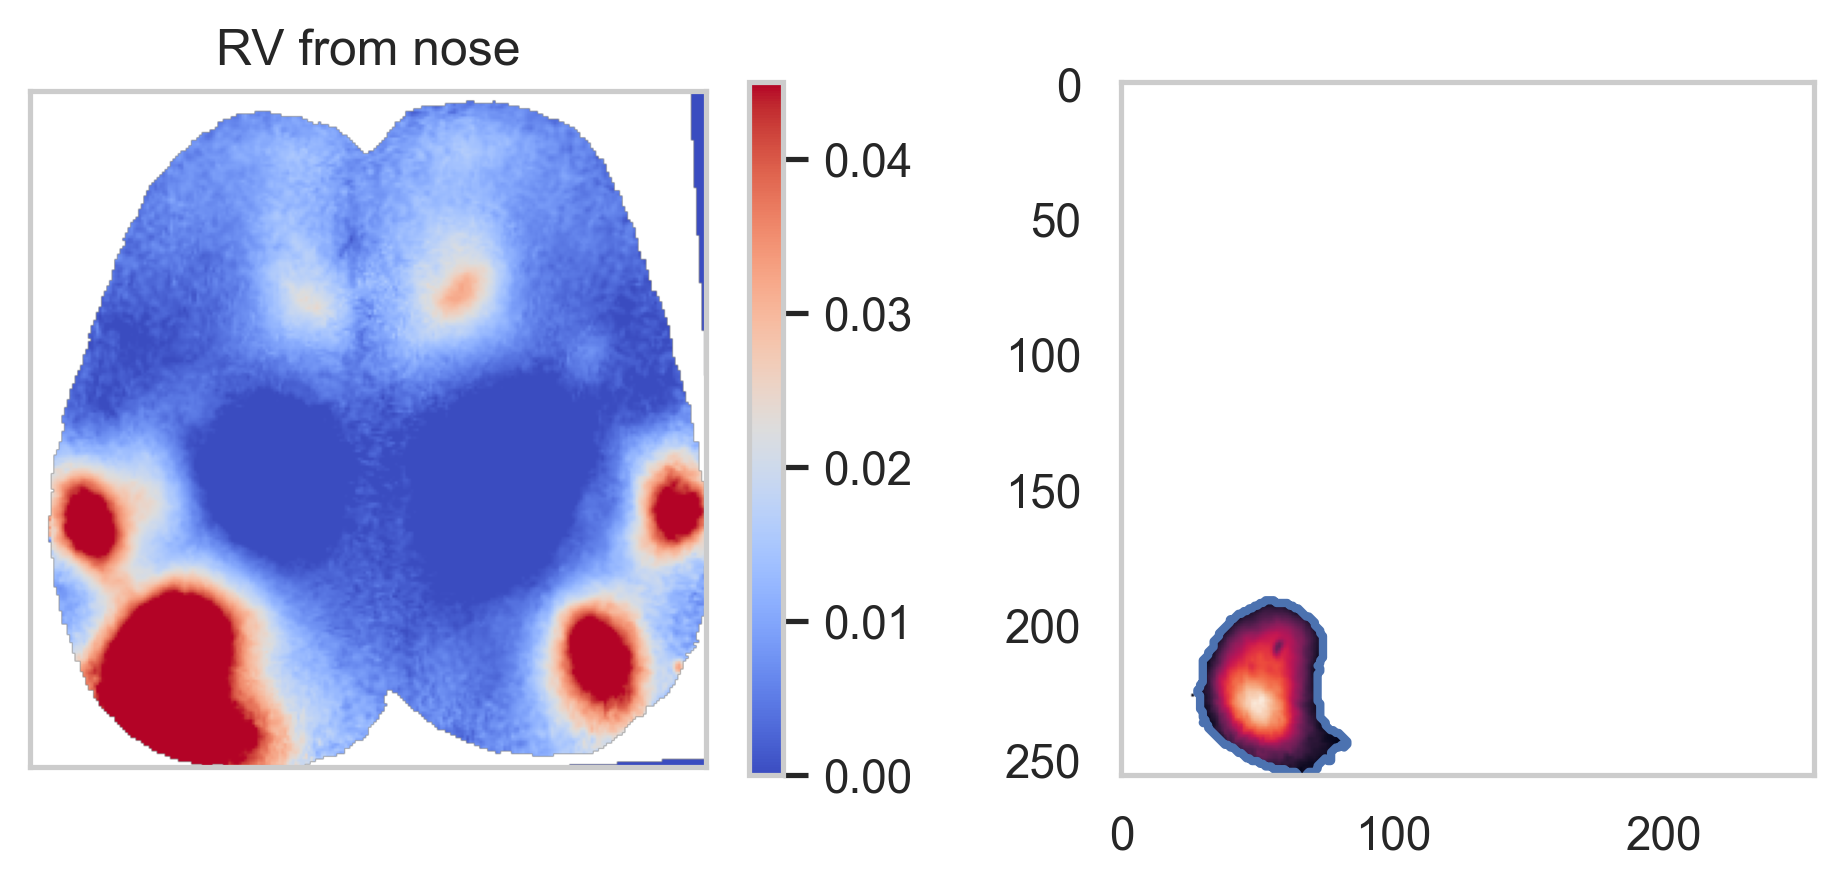

In [24]:
build_bodypart_roi(
    'RV', range(T_PRE, T_PRE + 20), vmax=0.045, bw_threshold=0.05,
    source_key='nose', stat_key='nose', title='RV from nose', focus_range=(0.2, 1),
    show_bw_preview=False, mask_crop=_crop_rv,
    reject_contour=lambda c: (
        np.any(c[:, 0] < 180) or np.any(c[:, 1] > 180) or len(c) < 30
    ),
)


array([[nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       ...,
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.],
       [nan, nan, nan, ...,  0.,  0.,  0.]], shape=(256, 256))

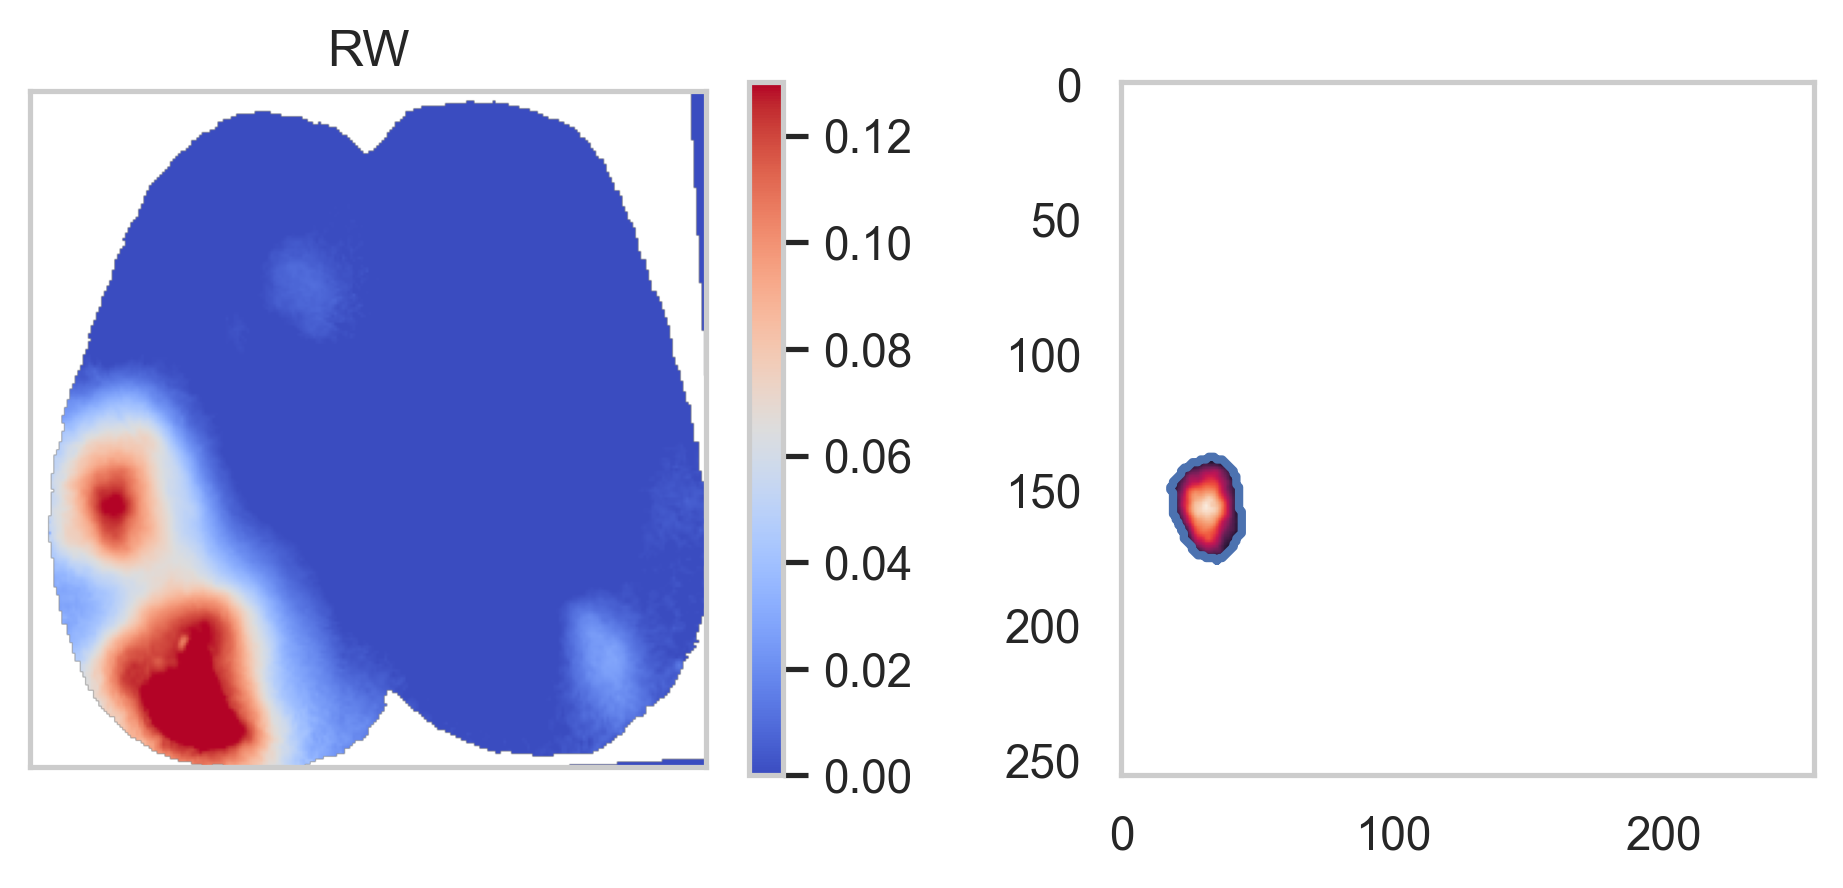

In [25]:
build_bodypart_roi(
    'RW', range(T_PRE, T_PRE + 80), vmax=0.13, bw_threshold=0.1 - 0.01,
    show_bw_preview=False,
    mask_crop=lambda bw: _crop_rows(bw, 185),
    reject_contour=_reject_default,
)


In [24]:
everything_dict = {
    # 'dict_M_jrgeco':M_jrgeco,
'avg_brain_maps':avg_brain_maps,
'contours':contours,
                  'clean_contours':clean_contours,
                   'brightest_ind':brightest_ind,
                   'vmax_dict':vmax_dict,
                   't_range_dict':t_range_dict,
                   'homunculus_rois':homunculus_rois
}


In [25]:
save_path=str(FIGURES / "figure1") + "/"
save_model(everything_dict,save_path+'sensory_homunculus_'+mouse)



In [26]:
save_model(clean_contours,save_path+'clean_contours_'+mouse)